GENERACIÓN DATOS SINTETICOS 

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from sklearn.linear_model import Lasso
from scipy.io import loadmat
from sklearn.metrics import mean_squared_error
from scipy.integrate import solve_ivp
from scipy.ndimage import laplace
import pysindy as ps

# Ignore matplotlib deprecation warnings
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

# Seed the random number generators for reproducibility
np.random.seed(100)

integrator_keywords = {}
integrator_keywords['rtol'] = 1e-12
integrator_keywords['method'] = 'LSODA'
integrator_keywords['atol'] = 1e-12

from numpy.fft import fft2, ifft2
integrator_keywords['method'] = 'RK45'  # switch to RK45 integrator

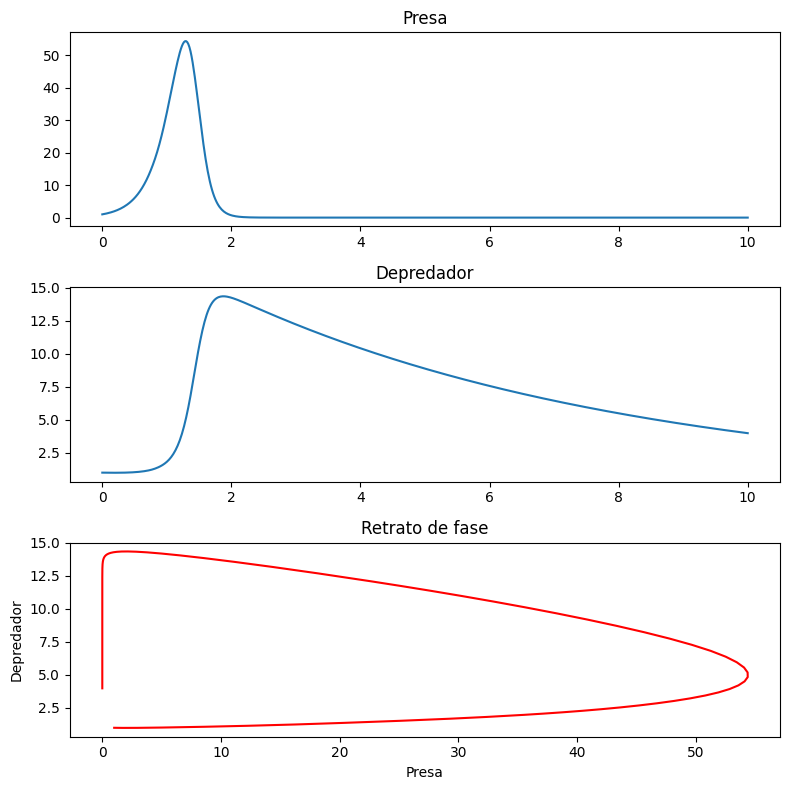

Datos guardados correctamente en resultado_data.xlsx


In [22]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
import scipy.io as sio

# Define the Lotka-Volterra ODE system
def rhs_dyn(t, y):
    a1 = 4.5
    b1 = 0.9
    a2 = 0.16
    b2 = 0.08

    dydt = [
        a1 * y[0] - b1 * y[0] * y[1],
        b2 * y[0] * y[1] - a2 * y[1]
    ]

    return dydt


# Simulation parameters
N = 600
t_span = (0.0, 10.0)

dt = (t_span[1] - t_span[0]) / N

t_eval = np.arange(t_span[0], t_span[1], dt)
t_eval = np.append(t_eval, t_span[1])

y0 = [1.0, 1.0]


# Integrate the ODE
sol = solve_ivp(
    rhs_dyn,
    t_span,
    y0,
    t_eval=t_eval,
    method='RK45'
)


# Extract the solution
t = sol.t
y = sol.y.T


# Plotting
plt.figure(figsize=(8, 8))

plt.subplot(3, 1, 1)
plt.plot(t, y[:, 0])
plt.title("Presa")

plt.subplot(3, 1, 2)
plt.plot(t, y[:, 1])
plt.title("Depredador")

plt.subplot(3, 1, 3)
plt.plot(y[:, 0], y[:, 1], 'r')
plt.title("Retrato de fase")
plt.xlabel("Presa")
plt.ylabel("Depredador")

plt.tight_layout()
plt.show()


# Guardar los datos en formato NPZ
np.savez('resultado_data.npz', t=t, y=y)


# Guardar los datos en Excel
df = pd.DataFrame({
    'Tiempo': t,
    'Presa': y[:, 0],
    'Depredador': y[:, 1]
})

df.to_excel('resultado_data.xlsx', index=False)

print("Datos guardados correctamente en resultado_data.xlsx")

# SINDy y Weak-SINDy: identificación y búsqueda reproducible
## Sistema datos sintéticos

Este notebook reúne dos objetivos:

1. **explicar cómo funcionan SINDy clásico y Weak-SINDy** sobre los mismos 600 datos;
2. **mostrar cómo se encontró la configuración seleccionada**, en lugar de presentar sus hiperparámetros como números elegidos a posteriori.

La lógica experimental será la misma en ambos métodos:

$$
\text{biblioteca candidata}
\rightarrow
\text{familia de configuraciones}
\rightarrow
\text{ajuste}
\rightarrow
\text{soporte}
\rightarrow
\text{integración}
\rightarrow
\text{métricas}
\rightarrow
\text{selección}.
$$

En Weak-SINDy se reproduce la búsqueda original de refinamiento: **14 040 ajustes STLSQ** y, cuando `SR3` está disponible, **90 ajustes SR3 selectivos**, para un máximo de **14 130 configuraciones**. En el experimento original con PySINDy 2.1.0 aparecieron **72 modelos con soporte exactamente tipo Lotka–Volterra**.

En SINDy clásico se realiza una búsqueda análoga, pero **no se fuerza artificialmente el mismo número de configuraciones**: SINDy clásico tiene menos hiperparámetros que Weak-SINDy. Esto es metodológicamente importante.

## 1. Dependencias y reproducibilidad

In [23]:
# Si hace falta:
# %pip install "pysindy>=2.0,<3" numpy pandas scipy matplotlib scikit-learn

from __future__ import annotations
import inspect
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import pysindy as ps

print("PySINDy:", ps.__version__)
print("STLSQ:", inspect.signature(ps.STLSQ))
print("SR3 disponible:", hasattr(ps, "SR3"))

PySINDy: 2.0.0
STLSQ: (threshold=0.1, alpha=0.05, max_iter=20, ridge_kw=None, normalize_columns=False, copy_X=True, initial_guess=None, verbose=False, sparse_ind=None, unbias=True)
SR3 disponible: True


## 2. Datos

Las observaciones son anuales, 1900--1920. Para el cálculo usamos
$t=0,\ldots,20$ y $\Delta t=1$. No se crean observaciones por interpolación.

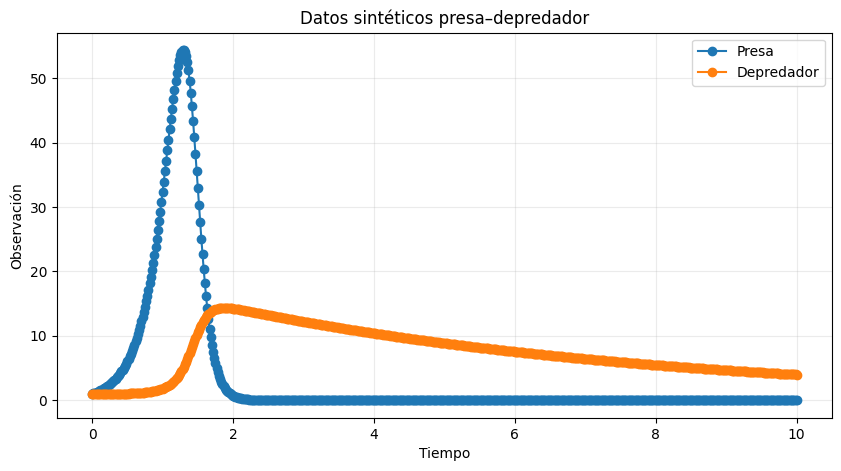

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CARGAR LOS DATOS DESDE EXCEL
# ============================================================

datos = pd.read_excel("resultado_data.xlsx")

# Extraer las columnas del Excel
t = datos["Tiempo"].values
hare = datos["Presa"].values
lynx = datos["Depredador"].values

# Paso de tiempo
dt = t[1] - t[0]

# ============================================================
# ORGANIZAR LOS DATOS
# ============================================================

X = np.column_stack([hare, lynx])

feature_names = ["x", "y"]

physical_feature_names = {
    "1",
    "x",
    "y",
    "x^2",
    "x*y",
    "y^2"
}

# ============================================================
# GRAFICAR LOS DATOS
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    t,
    hare,
    "o-",
    label="Presa"
)

ax.plot(
    t,
    lynx,
    "o-",
    label="Depredador"
)

ax.set(
    xlabel="Tiempo",
    ylabel="Observación",
    title="Datos sintéticos presa–depredador"
)

ax.legend()
ax.grid(alpha=.25)

plt.show()

## 3. Biblioteca común y criterio de ``soporte tipo Lotka--Volterra''

En ambos métodos usamos la misma biblioteca polinómica

$$
\Theta(x,y)=[1,x,y,x^2,xy,y^2].
$$

Decimos que un modelo tiene **soporte exactamente tipo Lotka--Volterra** cuando

$$
\dot x:\{x,xy\},\qquad
\dot y:\{y,xy\}.
$$

Esta definición evalúa la **estructura algebraica**, no presupone que Lotka--Volterra sea el modelo ecológico verdadero. También registraremos si los cuatro signos son los esperados:

$$
x>0,\quad xy<0 \quad\text{en }\dot x,
\qquad
y<0,\quad xy>0 \quad\text{en }\dot y.
$$

In [25]:
def canonicalize_name(name):
    v = name.replace(" ", "").replace("x0", "x").replace("x1", "y")
    v = v.replace("x**2", "x^2").replace("y**2", "y^2").replace("xy", "x*y")
    return v if v else "1"


def support_tuple(coef, names, eq, tol=1e-12):
    return tuple(
        names[j]
        for j in range(len(names))
        if abs(coef[eq, j]) > tol
    )


def lv_scores(coef, names):
    idx = {n: i for i, n in enumerate(names)}

    sx = set(support_tuple(coef, names, 0))
    sy = set(support_tuple(coef, names, 1))

    # Estructura esperada de Lotka-Volterra
    ex = {"x", "x*y"}
    ey = {"y", "x*y"}

    support_score = len(ex & sx) + len(ey & sy)

    sign_score = 0

    # dx/dt: término x positivo
    if "x" in idx:
        sign_score += int(coef[0, idx["x"]] > 0)

    # dy/dt: término y negativo
    if "y" in idx:
        sign_score += int(coef[1, idx["y"]] < 0)

    # dx/dt: término x*y negativo
    # dy/dt: término x*y positivo
    if "x*y" in idx:
        sign_score += int(coef[0, idx["x*y"]] < 0)
        sign_score += int(coef[1, idx["x*y"]] > 0)

    exact = int(sx == ex and sy == ey)

    return support_score, sign_score, exact


def global_r2(obs, pred):
    rss = np.sum((obs - pred) ** 2)

    tss = np.sum(
        (obs - obs.mean(axis=0, keepdims=True)) ** 2
    )

    return 1 - rss / tss


def library_vector(state, names):
    x, y = map(float, state)

    vals = {
        "1": 1.0,
        "x": x,
        "y": y,
        "x^2": x * x,
        "x*y": x * y,
        "y^2": y * y
    }

    return np.array([vals[n] for n in names])


def safe_simulate(coef, names, times, x0):

    try:

        if not np.all(np.isfinite(coef)):
            return False, None

        if np.max(np.abs(coef)) > 1000:
            return False, None

        def rhs(_, state):

            if np.max(np.abs(state)) > 250 or np.min(state) < -5:
                raise FloatingPointError

            val = coef @ library_vector(state, names)

            if not np.all(np.isfinite(val)):
                raise FloatingPointError

            if np.max(np.abs(val)) > 2000:
                raise FloatingPointError

            return val

        sol = solve_ivp(
            rhs,
            (float(times[0]), float(times[-1])),
            x0,
            t_eval=times,
            rtol=1e-6,
            atol=1e-8,
            max_step=.25
        )

        if not sol.success or sol.y.shape[1] != len(times):
            return False, None

        Y = sol.y.T

        if not np.all(np.isfinite(Y)):
            return False, None

        if np.max(np.abs(Y)) > 250:
            return False, None

        if np.min(Y) < -5:
            return False, None

        return True, Y

    except Exception:
        return False, None


def summarize_fit(coef, names):

    ss, sg, ex = lv_scores(coef, names)

    ok, Y = safe_simulate(
        coef,
        names,
        t,
        X[0]
    )

    rmse = (
        np.sqrt(np.mean((Y - X) ** 2))
        if ok
        else np.inf
    )

    r2 = (
        global_r2(X, Y)
        if ok
        else -np.inf
    )

    return dict(
        n_active_total=int(
            np.count_nonzero(
                np.abs(coef) > 1e-12
            )
        ),

        support_hare="|".join(
            support_tuple(coef, names, 0)
        ),

        support_lynx="|".join(
            support_tuple(coef, names, 1)
        ),

        lv_support_score=ss,

        lv_sign_score=sg,

        exact_lv_support=ex,

        trajectory_success=ok,

        trajectory_rmse=float(rmse),

        trajectory_r2=float(r2)
    )

# PARTE A — SINDy clásico

## 4. ¿Qué cambia en SINDy clásico?

SINDy clásico necesita una estimación puntual de \(\dot X\):

$$
\dot X\approx\Theta(X)\Xi.
$$

s¿Se tienen 600 datos en donde, la diferenciación numérica es una parte sensible del procedimiento. En esta comparación docente mantenemos fija la diferenciación predeterminada de PySINDy y exploramos sistemáticamente los hiperparámetros de STLSQ.

La búsqueda clásica no tiene $K,H_{xt},p$, porque esos parámetros pertenecen a la formulación débil.

In [26]:
classic_thresholds=np.unique(np.r_[0.0,np.logspace(-3,3,25)]).tolist()
classic_alphas=[1e-10,1e-8,1e-6]
classic_normalize=[True,False]

classic_total=len(classic_thresholds)*len(classic_alphas)*len(classic_normalize)
print("Configuraciones SINDy clásico:",classic_total)

Configuraciones SINDy clásico: 156


In [27]:
def fit_classic_sindy(threshold,alpha,normalize_columns):
    lib=ps.PolynomialLibrary(degree=2,include_bias=True,interaction_only=False)
    opt=ps.STLSQ(threshold=float(threshold),alpha=float(alpha),
                 normalize_columns=bool(normalize_columns),max_iter=200)
    model=ps.SINDy(feature_library=lib,optimizer=opt)
    model.fit(X,t=dt,feature_names=feature_names)
    coef=np.asarray(model.coefficients(),float)
    names=[canonicalize_name(n) for n in model.get_feature_names()]
    summary=summarize_fit(coef,names)
    return {**summary,"threshold":threshold,"alpha":alpha,
            "normalize_columns":normalize_columns,
            "coefficients":coef,"library_names":names}

## 5. Exploración de SINDy clásico

Cada fila de la tabla siguiente es un experimento reproducible. Así podemos mostrar al jurado que el modelo seleccionado no proviene de probar manualmente un único `threshold`.

In [28]:
classic_experiments = []
classic_failures = []

for norm in classic_normalize:
    for alpha in classic_alphas:
        for threshold in classic_thresholds:
            try:
                classic_experiments.append(
                    fit_classic_sindy(threshold, alpha, norm)
                )
            except Exception as e:
                classic_failures.append(
                    (threshold, alpha, norm, type(e).__name__)
                )

classic_table = pd.DataFrame([
    {k: v for k, v in e.items()
     if k not in {"coefficients", "library_names"}}
    for e in classic_experiments
])

print("Ajustes exitosos:", len(classic_experiments))
print("Fallos:", len(classic_failures))
print("Soporte LV exacto:", int(classic_table["exact_lv_support"].sum()))

display(
    classic_table.sort_values(
        ["exact_lv_support",
         "lv_sign_score",
         "lv_support_score",
         "trajectory_rmse"],
        ascending=[False, False, False, True]
    ).head(15)
)

Ajustes exitosos: 156
Fallos: 0
Soporte LV exacto: 15


,n_active_total,support_hare,support_lynx,lv_support_score,lv_sign_score,exact_lv_support,trajectory_success,trajectory_rmse,trajectory_r2,threshold,alpha,normalize_columns
18,4,x|x*y,y|x*y,4,4,1,True,0.146686,0.999676,17.782794,1.000000e-10,True
19,4,x|x*y,y|x*y,4,4,1,True,0.146686,0.999676,31.622777,1.000000e-10,True
44,4,x|x*y,y|x*y,4,4,1,True,0.146686,0.999676,17.782794,1.000000e-08,True
45,4,x|x*y,y|x*y,4,4,1,True,0.146686,0.999676,31.622777,1.000000e-08,True
70,4,x|x*y,y|x*y,4,4,1,True,0.146686,0.999676,17.782794,1.000000e-06,True
71,4,x|x*y,y|x*y,4,4,1,True,0.146686,0.999676,31.622777,1.000000e-06,True
84,4,x|x*y,y|x*y,4,4,1,True,0.146686,0.999676,0.017783,1.000000e-10,False
85,4,x|x*y,y|x*y,4,4,1,True,0.146686,0.999676,0.031623,1.000000e-10,False
86,4,x|x*y,y|x*y,4,4,1,True,0.146686,0.999676,0.056234,1.000000e-10,False
110,4,x|x*y,y|x*y,4,4,1,True,0.146686,0.999676,0.017783,1.000000e-08,False


## 6. Selección transparente en SINDy clásico

Usamos una regla jerárquica explícita:

1. soporte LV exacto;
2. cuatro signos correctos;
3. mayor recuperación de mecanismos LV;
4. menor número de términos;
5. menor RMSE entre los modelos que superaron los criterios anteriores.

El RMSE **no es el primer criterio**.

In [29]:
classic_ok = classic_table[classic_table["trajectory_success"]].copy()

classic_ok["extra_terms"] = (
    classic_ok["n_active_total"] - classic_ok["lv_support_score"]
)

best_classic_row = classic_ok.sort_values(
    ["exact_lv_support",
     "lv_sign_score",
     "lv_support_score",
     "extra_terms",
     "trajectory_rmse"],
    ascending=[False, False, False, True, True]
).iloc[0]

best_classic = next(
    e for e in classic_experiments
    if np.isclose(e["threshold"], best_classic_row["threshold"])
    and np.isclose(e["alpha"], best_classic_row["alpha"])
    and e["normalize_columns"] == bool(
        best_classic_row["normalize_columns"]
    )
)

display(
    best_classic_row.to_frame("SINDy seleccionado").T
)

print("Coeficientes:\n", best_classic["coefficients"])

,n_active_total,support_hare,support_lynx,lv_support_score,lv_sign_score,exact_lv_support,trajectory_success,trajectory_rmse,trajectory_r2,threshold,alpha,normalize_columns,extra_terms
SINDy seleccionado,4,x|x*y,y|x*y,4,4,1,True,0.146686,0.999676,17.782794,0.0,True,0


Coeficientes:
 [[ 0.          4.4740569   0.          0.         -0.89426258  0.        ]
 [ 0.          0.         -0.15995932  0.          0.0797878   0.        ]]


# PARTE B — Weak-SINDy

## 7. Forma débil y parámetros adicionales

Weak-SINDy parte de

$$
-\int_{I_k}\dot\phi_k(t)\mathbf{x}(t)\,dt
=
\int_{I_k}\phi_k(t)F(\mathbf{x}(t))\,dt,
$$

y construye un sistema $B\approx G\Xi$. Aparecen entonces parámetros adicionales relacionados con las funciones de prueba y sus ventanas: $K,H_{xt},p$.

Por eso la búsqueda Weak-SINDy es mucho mayor.

In [30]:
SEED = 20260803
seeds = [SEED + i for i in range(5)]

K_values = [40, 50, 60]
H_xt_values = [2.5, 3.0, 3.5]
p_values = [3, 4]

weak_thresholds = np.unique(
    np.r_[0.0, np.logspace(-3, 3, 25)]
).tolist()

weak_normalize = [True, False]
weak_alphas = [1e-10, 1e-8, 1e-6]

stlsq_total = (
    len(seeds)
    * len(K_values)
    * len(H_xt_values)
    * len(p_values)
    * len(weak_thresholds)
    * len(weak_normalize)
    * len(weak_alphas)
)

print("Weak-SINDy STLSQ:", stlsq_total)  # 14040
print("SR3 selectivo, si está disponible:", 5 * 9 * 2)  # 90
print("Máximo total:", stlsq_total + 5 * 9 * 2)  # 14130

Weak-SINDy STLSQ: 14040
SR3 selectivo, si está disponible: 90
Máximo total: 14130


In [31]:
def build_weak_library(seed, K, H_xt, p):
    np.random.seed(int(seed))

    poly = ps.PolynomialLibrary(
        degree=2,
        include_bias=False,
        interaction_only=False
    )

    lib = ps.WeakPDELibrary(
        function_library=poly,
        derivative_order=0,
        spatiotemporal_grid=t,
        include_bias=True,
        K=int(K),
        H_xt=float(H_xt),
        p=int(p)
    )

    if not hasattr(lib, "is_uniform"):
        lib.is_uniform = None

    if not hasattr(lib, "periodic"):
        lib.periodic = None

    return lib


def fit_weak_stlsq(
    seed, K, H_xt, p, threshold, alpha, normalize_columns
):
    lib = build_weak_library(seed, K, H_xt, p)

    opt = ps.STLSQ(
        threshold=float(threshold),
        alpha=float(alpha),
        normalize_columns=bool(normalize_columns),
        max_iter=200
    )

    model = ps.SINDy(
        feature_library=lib,
        optimizer=opt
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(
            X,
            t=dt,
            feature_names=feature_names
        )

    coef = np.asarray(model.coefficients(), float)

    names = [
        canonicalize_name(n)
        for n in model.get_feature_names()
    ]

    summary = summarize_fit(coef, names)

    return {
        **summary,
        "optimizer_family": "STLSQ",
        "seed": seed,
        "K": K,
        "H_xt": H_xt,
        "p": p,
        "threshold": threshold,
        "alpha": alpha,
        "normalize_columns": normalize_columns,
        "coefficients": coef,
        "library_names": names
    }

## 8. Búsqueda exhaustiva STLSQ: 14 040 configuraciones

Esta es la parte que explica el origen de la configuración reproducible. Puede tardar varios minutos según el computador.

Para una demostración rápida se puede poner `FAST_MODE=True`; para reproducir el hallazgo original debe permanecer en `False`.

In [32]:
FAST_MODE=False

if FAST_MODE:
    run_seeds=seeds[:2]; run_K=[50]; run_H=[3.0]; run_p=[3]
    run_thresholds=[0.1,1.0,10.0,100.0]; run_norm=[True,False]; run_alpha=[1e-8]
else:
    run_seeds=seeds; run_K=K_values; run_H=H_xt_values; run_p=p_values
    run_thresholds=weak_thresholds; run_norm=weak_normalize; run_alpha=weak_alphas

planned=(len(run_seeds)*len(run_K)*len(run_H)*len(run_p)*
         len(run_thresholds)*len(run_norm)*len(run_alpha))
print("Ajustes STLSQ planificados:",planned)

weak_experiments=[]
weak_failures=[]
counter=0

for seed in run_seeds:
    for K in run_K:
        for H in run_H:
            for p in run_p:
                for norm in run_norm:
                    for alpha in run_alpha:
                        for threshold in run_thresholds:
                            counter+=1
                            try:
                                weak_experiments.append(
                                    fit_weak_stlsq(seed,K,H,p,threshold,alpha,norm)
                                )
                            except Exception as e:
                                weak_failures.append(
                                    dict(seed=seed,K=K,H_xt=H,p=p,threshold=threshold,
                                         alpha=alpha,normalize_columns=norm,
                                         error=type(e).__name__)
                                )
                            if counter%500==0 or counter==planned:
                                exact=sum(e["exact_lv_support"] for e in weak_experiments)
                                print(f"{counter}/{planned} | éxitos={len(weak_experiments)} "
                                      f"| fallos={len(weak_failures)} | LV exactos={exact}")

Ajustes STLSQ planificados: 14040
500/14040 | éxitos=500 | fallos=0 | LV exactos=140
1000/14040 | éxitos=1000 | fallos=0 | LV exactos=277
1500/14040 | éxitos=1500 | fallos=0 | LV exactos=422
2000/14040 | éxitos=2000 | fallos=0 | LV exactos=559
2500/14040 | éxitos=2500 | fallos=0 | LV exactos=700
3000/14040 | éxitos=3000 | fallos=0 | LV exactos=835
3500/14040 | éxitos=3500 | fallos=0 | LV exactos=969
4000/14040 | éxitos=4000 | fallos=0 | LV exactos=1103
4500/14040 | éxitos=4500 | fallos=0 | LV exactos=1238
5000/14040 | éxitos=5000 | fallos=0 | LV exactos=1371
5500/14040 | éxitos=5500 | fallos=0 | LV exactos=1512
6000/14040 | éxitos=6000 | fallos=0 | LV exactos=1646
6500/14040 | éxitos=6500 | fallos=0 | LV exactos=1777
7000/14040 | éxitos=7000 | fallos=0 | LV exactos=1924
7500/14040 | éxitos=7500 | fallos=0 | LV exactos=2052
8000/14040 | éxitos=8000 | fallos=0 | LV exactos=2197
8500/14040 | éxitos=8500 | fallos=0 | LV exactos=2332
9000/14040 | éxitos=9000 | fallos=0 | LV exactos=2470
950

## 9. SR3 selectivo: 90 configuraciones adicionales

El experimento original añadió una comparación selectiva con SR3:

\[
5\text{ semillas}\times9\text{ umbrales}\times2\text{ normalizaciones}=90.
\]

Así,

\[
14040+90=14130.
\]

La ejecución depende de que la versión instalada de PySINDy incluya `SR3`.

In [33]:
def build_sr3(threshold,normalize_columns):
    sig=inspect.signature(ps.SR3)
    pars=sig.parameters
    kw={}
    if "threshold" in pars: kw["threshold"]=float(threshold)
    if "thresholder" in pars: kw["thresholder"]="l0"
    if "nu" in pars: kw["nu"]=1.0
    if "max_iter" in pars: kw["max_iter"]=2000
    if "tol" in pars: kw["tol"]=1e-8
    if "normalize_columns" in pars: kw["normalize_columns"]=bool(normalize_columns)
    return ps.SR3(**kw)

def fit_weak_sr3(seed,threshold,normalize_columns):
    K,H,p=50,3.0,3
    lib=build_weak_library(seed,K,H,p)
    opt=build_sr3(threshold,normalize_columns)
    model=ps.SINDy(feature_library=lib,optimizer=opt)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(X,t=dt,feature_names=feature_names)
    coef=np.asarray(model.coefficients(),float)
    names=[canonicalize_name(n) for n in model.get_feature_names()]
    summary=summarize_fit(coef,names)
    return {**summary,"optimizer_family":"SR3","seed":seed,"K":K,"H_xt":H,"p":p,
            "threshold":threshold,"alpha":0.0,
            "normalize_columns":normalize_columns,
            "coefficients":coef,"library_names":names}

if (not FAST_MODE) and hasattr(ps,"SR3"):
    sr3_thresholds=[0.01,0.03,0.1,0.3,1.0,3.0,10.0,30.0,100.0]
    for seed in seeds:
        for norm in weak_normalize:
            for threshold in sr3_thresholds:
                try:
                    weak_experiments.append(fit_weak_sr3(seed,threshold,norm))
                except Exception as e:
                    weak_failures.append(dict(optimizer_family="SR3",seed=seed,
                                              threshold=threshold,
                                              normalize_columns=norm,
                                              error=type(e).__name__))
else:
    print("SR3 omitido (FAST_MODE o SR3 no disponible).")

## 10. ¿Aparecen los 72 soportes exactos?

Con `FAST_MODE=False`, PySINDy 2.1.0 y el mismo entorno del experimento original, la referencia es:

- configuraciones máximas: **14 130**;
- modelos con soporte exactamente LV: **72**.

La celda no fuerza esos números: los vuelve a calcular. Esa diferencia es esencial para una demostración reproducible.

In [34]:
weak_table=pd.DataFrame([
    {k:v for k,v in e.items() if k not in {"coefficients","library_names"}}
    for e in weak_experiments
])

print("Resultados exitosos:",len(weak_experiments))
print("Fallos:",len(weak_failures))
print("Soporte exactamente LV:",int(weak_table["exact_lv_support"].sum()))

exact_weak=weak_table[weak_table["exact_lv_support"]==1].copy()
display(exact_weak.sort_values(
    ["lv_sign_score","trajectory_success","trajectory_rmse"],
    ascending=[False,False,True]).head(20))

Resultados exitosos: 14130
Fallos: 0
Soporte exactamente LV: 3863


,n_active_total,support_hare,support_lynx,lv_support_score,lv_sign_score,exact_lv_support,trajectory_success,trajectory_rmse,trajectory_r2,optimizer_family,seed,K,H_xt,p,threshold,alpha,normalize_columns
12020,4,x|x*y,y|x*y,4,4,1,True,0.047868,0.999965,STLSQ,20260807,40,3.5,4,0.056234,1.000000e-10,True
12021,4,x|x*y,y|x*y,4,4,1,True,0.047868,0.999965,STLSQ,20260807,40,3.5,4,0.100000,1.000000e-10,True
12022,4,x|x*y,y|x*y,4,4,1,True,0.047868,0.999965,STLSQ,20260807,40,3.5,4,0.177828,1.000000e-10,True
12023,4,x|x*y,y|x*y,4,4,1,True,0.047868,0.999965,STLSQ,20260807,40,3.5,4,0.316228,1.000000e-10,True
12024,4,x|x*y,y|x*y,4,4,1,True,0.047868,0.999965,STLSQ,20260807,40,3.5,4,0.562341,1.000000e-10,True
12025,4,x|x*y,y|x*y,4,4,1,True,0.047868,0.999965,STLSQ,20260807,40,3.5,4,1.000000,1.000000e-10,True
12026,4,x|x*y,y|x*y,4,4,1,True,0.047868,0.999965,STLSQ,20260807,40,3.5,4,1.778279,1.000000e-10,True
12047,4,x|x*y,y|x*y,4,4,1,True,0.047868,0.999965,STLSQ,20260807,40,3.5,4,0.100000,1.000000e-08,True
12048,4,x|x*y,y|x*y,4,4,1,True,0.047868,0.999965,STLSQ,20260807,40,3.5,4,0.177828,1.000000e-08,True
12049,4,x|x*y,y|x*y,4,4,1,True,0.047868,0.999965,STLSQ,20260807,40,3.5,4,0.316228,1.000000e-08,True


## 11. Selección jerárquica de Weak-SINDy

Aplicamos exactamente la misma filosofía usada en SINDy clásico. La solución elegida debe emerger de una regla explícita, no de inspección visual.

In [35]:
weak_ok=weak_table[weak_table["trajectory_success"]].copy()
weak_ok["extra_terms"]=weak_ok["n_active_total"]-weak_ok["lv_support_score"]

best_weak_row=weak_ok.sort_values(
    ["exact_lv_support","lv_sign_score","lv_support_score","extra_terms","trajectory_rmse"],
    ascending=[False,False,False,True,True]).iloc[0]

def matches(e,row):
    keys=["optimizer_family","seed","K","p","normalize_columns"]
    if any(e[k]!=row[k] for k in keys): return False
    return (np.isclose(e["H_xt"],row["H_xt"]) and
            np.isclose(e["threshold"],row["threshold"]) and
            np.isclose(e["alpha"],row["alpha"]))

best_weak=next(e for e in weak_experiments if matches(e,best_weak_row))
display(best_weak_row.to_frame("Weak-SINDy seleccionado").T)
print("Coeficientes:\n",best_weak["coefficients"])

,n_active_total,support_hare,support_lynx,lv_support_score,lv_sign_score,exact_lv_support,trajectory_success,trajectory_rmse,trajectory_r2,optimizer_family,seed,K,H_xt,p,threshold,alpha,normalize_columns,extra_terms
Weak-SINDy seleccionado,4,x|x*y,y|x*y,4,4,1,True,0.047868,0.999965,STLSQ,20260807,40,3.5,4,0.056234,0.0,True,0


Coeficientes:
 [[ 0.          4.49674523  0.          0.         -0.89800828  0.        ]
 [ 0.          0.         -0.16000104  0.          0.07983072  0.        ]]


In [ ]:
#REFERENCE_WEAK = {
#    "seed":20260807,"K":50,"H_xt":3.5,"p":3,
 #   "threshold":316.22776601683796,"alpha":1e-10,
#    "normalize_columns":True
#
#reference_fit=fit_weak_stlsq(**REFERENCE_WEAK)

#print("Coeficientes de la configuración de referencia:")
#print(reference_fit["coefficients"])
#print("RMSE:",reference_fit["trajectory_rmse"])
#print("R²:",reference_fit["trajectory_r2"])
#print("Soporte LV exacto:",bool(reference_fit["exact_lv_support"]))

Coeficientes de la configuración de referencia:
[[0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]
RMSE: 9.549292760252406
R²: -0.3740942686556228
Soporte LV exacto: False


# PARTE C — Comparación final

## 13. SINDy vs Weak-SINDy

La comparación debe separar dos preguntas:

1. **¿qué estructura identifica cada método?**
2. **¿qué tan bien reproduce la trayectoria observada el modelo integrado?**

Un RMSE menor no basta para declarar un modelo científicamente preferible si requiere muchos términos adicionales.

In [37]:
comparison = pd.DataFrame([
    {
        "metodo": "SINDy clásico",
        "soporte_presa": best_classic["support_hare"],
        "soporte_depredador": best_classic["support_lynx"],
        "terminos": best_classic["n_active_total"],
        "LV_exacto": bool(best_classic["exact_lv_support"]),
        "signos_LV": best_classic["lv_sign_score"],
        "RMSE": best_classic["trajectory_rmse"],
        "R2": best_classic["trajectory_r2"]
    },
    {
        "metodo": "Weak-SINDy",
        "soporte_presa": best_weak["support_hare"],
        "soporte_depredador": best_weak["support_lynx"],
        "terminos": best_weak["n_active_total"],
        "LV_exacto": bool(best_weak["exact_lv_support"]),
        "signos_LV": best_weak["lv_sign_score"],
        "RMSE": best_weak["trajectory_rmse"],
        "R2": best_weak["trajectory_r2"]
    }
])

display(comparison)

,metodo,soporte_presa,soporte_depredador,terminos,LV_exacto,signos_LV,RMSE,R2
0,SINDy clásico,x|x*y,y|x*y,4,True,4,0.146686,0.999676
1,Weak-SINDy,x|x*y,y|x*y,4,True,4,0.047868,0.999965


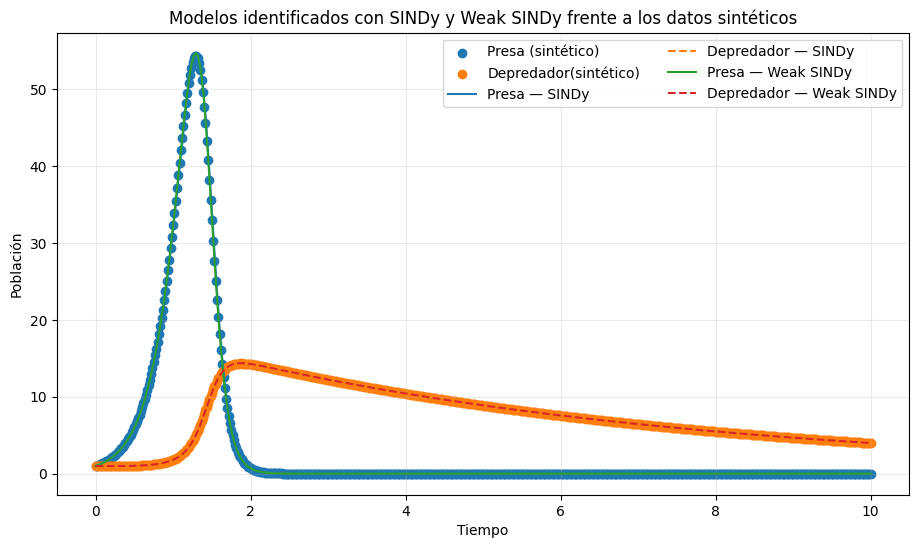

In [38]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(t, hare, label="Presa (sintético)")
ax.scatter(t, lynx, label="Depredador(sintético)")

for label, e in [
    ("SINDy", best_classic),
    ("Weak SINDy", best_weak)
]:
    ok, Y = safe_simulate(
        e["coefficients"],
        e["library_names"],
        t,
        X[0]
    )

    if ok:
        ax.plot(
            t,
            Y[:, 0],
            label=f"Presa — {label}"
        )

        ax.plot(
            t,
            Y[:, 1],
            "--",
            label=f"Depredador — {label}"
        )

ax.set(
    xlabel="Tiempo",
    ylabel="Población",
    title="Modelos identificados con SINDy y Weak SINDy frente a los datos sintéticos"
)

ax.legend(ncol=2)
ax.grid(alpha=.25)
plt.show()

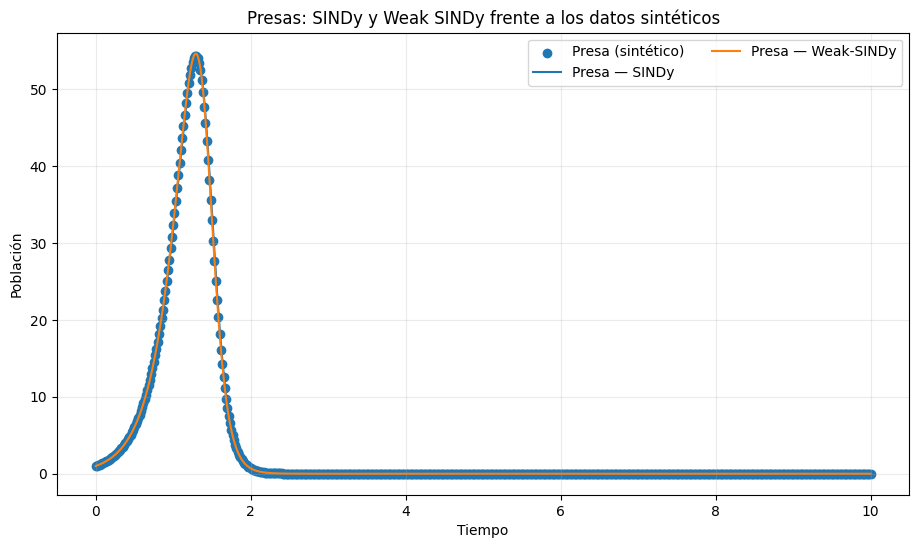

In [40]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(t, hare, label="Presa (sintético)")

for label, e in [
    ("SINDy", best_classic),
    ("Weak-SINDy", best_weak)
]:
    ok, Y = safe_simulate(
        e["coefficients"],
        e["library_names"],
        t,
        X[0]
    )

    if ok:
        ax.plot(
            t,
            Y[:, 0],
            label=f"Presa — {label}"
        )

ax.set(
    xlabel="Tiempo",
    ylabel="Población",
    title="Presas: SINDy y Weak SINDy frente a los datos sintéticos"
)

ax.legend(ncol=2)
ax.grid(alpha=.25)
plt.show()

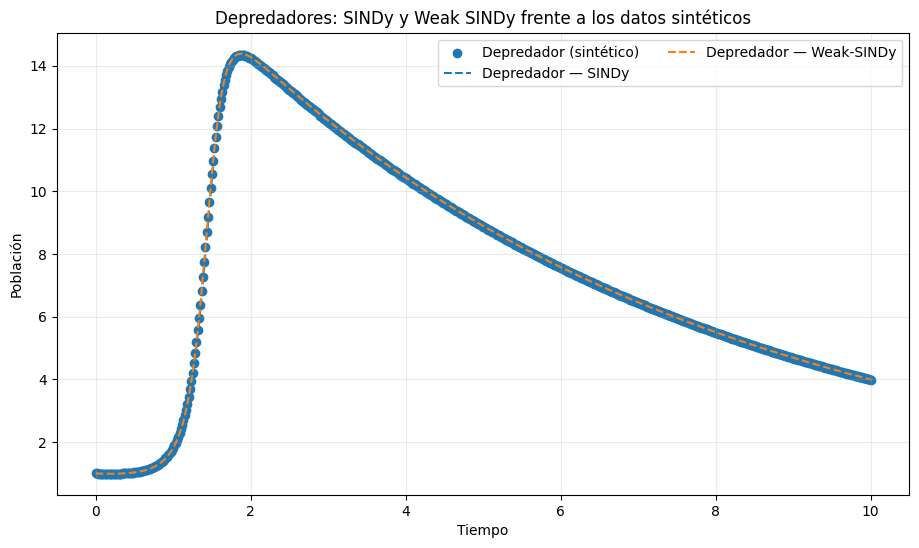

In [41]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(t, lynx, label="Depredador (sintético)")

for label, e in [
    ("SINDy", best_classic),
    ("Weak-SINDy", best_weak)
]:
    ok, Y = safe_simulate(
        e["coefficients"],
        e["library_names"],
        t,
        X[0]
    )

    if ok:
       
        ax.plot(
            t,
            Y[:, 1],
            "--",
            label=f"Depredador — {label}"
        )

ax.set(
    xlabel="Tiempo",
    ylabel="Población",
    title="Depredadores: SINDy y Weak SINDy frente a los datos sintéticos"
)

ax.legend(ncol=2)
ax.grid(alpha=.25)
plt.show()